In [1]:

# Cell 1: Import libraries and locate the existing dataset

from pathlib import Path
import pandas as pd
import numpy as np

# Existing Swiggy project dataset
DATA_PATH = Path(r"C:\Users\ASUS\Downloads\swiggy_file.csv\swiggy_cleaned.csv")

print("Dataset exists:", DATA_PATH.exists())
print("Dataset path:", DATA_PATH)

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)

    print("\nDataset loaded successfully!")
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst five rows:")
    display(df.head())

    print("\nTarget column available:", "average_price" in df.columns)
else:
    print("\nDataset not found at this path.")
    print("Update DATA_PATH to the actual location of swiggy_cleaned.csv.")


Dataset exists: False
Dataset path: C:\Users\ASUS\Downloads\swiggy_file.csv\swiggy_cleaned.csv

Dataset not found at this path.
Update DATA_PATH to the actual location of swiggy_cleaned.csv.


In [2]:

from pathlib import Path

search_locations = [
    Path.home() / "Downloads",
    Path.home() / "Documents",
    Path.home() / "Desktop",
    Path.home() / "Swiggy",
    Path(r"C:\Users\ASUS"),
]

matches = []

for folder in search_locations:
    if folder.exists():
        print("Searching:", folder)
        try:
            for file in folder.rglob("swiggy_cleaned.csv"):
                matches.append(file)
        except (PermissionError, OSError):
            pass

print("\nSearch complete.")
print("Files found:", len(set(matches)))

for file in dict.fromkeys(matches):
    print(file)


Searching: C:\Users\ASUS\Downloads
Searching: C:\Users\ASUS\Documents
Searching: C:\Users\ASUS

Search complete.
Files found: 1
C:\Users\ASUS\Downloads\swiggy_cleaned.csv


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_PATH = Path(r"C:\Users\ASUS\Downloads\swiggy_cleaned.csv")

df = pd.read_csv(DATA_PATH)

print("✅ Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget column available:", "average_price" in df.columns)

display(df.head())

✅ Dataset loaded successfully!
Dataset shape: (139321, 10)

Columns:
['restaurant_name', 'cuisine', 'rating', 'number_of_ratings', 'average_price', 'number_of_offers', 'offer_name', 'area', 'pure_veg', 'location']

Target column available: True


,restaurant_name,cuisine,rating,number_of_ratings,average_price,number_of_offers,offer_name,area,pure_veg,location
0,La Pino'Z Pizza,"Pizzas, Pastas",4.0,10.0,250,2,FLAT DEAL\nFLAT ₹125 OFF\nUSE FLAT125ABOVE ₹69...,LALA LAJPAT RAI MARKET,No,Abohar
1,The Second Wife,"Indian, North Indian",3.6,50.0,250,2,"30% OFF UPTO ₹75\nUSE TRYNEWABOVE ₹149, FLAT ₹...",Central Abohar,No,Abohar
2,Tasty Bites,"Italian, Beverages",3.8,10.0,200,1,FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500,Central Abohar,Yes,Abohar
3,Food Studio,"Pizzas, Burgers",3.5,8.0,49,5,"50% OFF UPTO ₹100\nUSE TRYNEWABOVE ₹129, FLAT ...",Central Abohar,Yes,Abohar
4,Roll Express,"Fast Food, Snacks",4.3,100.0,200,2,DEAL OF DAY\n10% OFF UPTO ₹40\nUSE STEALDEALAB...,Circular Road,No,Abohar


In [4]:
from sklearn.model_selection import train_test_split

FEATURES = [
    "cuisine",
    "rating",
    "number_of_ratings",
    "number_of_offers",
    "offer_name",
    "area",
    "pure_veg",
    "location"
]

TARGET = "average_price"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in target:", y.isna().sum())
print("Missing values in features:", X.isna().sum().sum())

assert y.notna().all(), "Target contains missing values. Handle these before splitting."

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\n✅ Train-test split completed!")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of features:", X_train.shape[1])

Features shape: (139321, 8)
Target shape: (139321,)

Missing values in target: 0
Missing values in features: 66914

✅ Train-test split completed!
Training rows: 111456
Testing rows: 27865
Number of features: 8


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC_FEATURES = [
    "rating",
    "number_of_ratings",
    "number_of_offers"
]

CATEGORICAL_FEATURES = [
    "cuisine",
    "offer_name",
    "area",
    "pure_veg",
    "location"
]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

print("✅ Numeric pipeline ready")
print("✅ Categorical pipeline ready")
print("✅ Combined preprocessing pipeline ready")

✅ Numeric pipeline ready
✅ Categorical pipeline ready
✅ Combined preprocessing pipeline ready


In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from time import time

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training started...")
start_time = time()

model.fit(X_train, y_train)

training_time = time() - start_time

print("\n✅ Model training completed!")
print(f"Training time: {training_time:.2f} seconds")
print("Training samples:", len(X_train))
print("Model: Random Forest Regressor")

Training started...

✅ Model training completed!
Training time: 36.14 seconds
Training samples: 111456
Model: Random Forest Regressor


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predict prices for unseen test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display results
results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Value": [mae, rmse, r2]
})

print("MODEL EVALUATION RESULTS")
display(results.round(4))

print(f"\nMAE: ₹{mae:.2f}")
print(f"RMSE: ₹{rmse:.2f}")
print(f"R² Score: {r2:.4f}")

MODEL EVALUATION RESULTS


,Metric,Value
0,MAE,86.8943
1,RMSE,142.9538
2,R² Score,0.0935



MAE: ₹86.89
RMSE: ₹142.95
R² Score: 0.0935


In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Train a simple baseline
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)

# Predictions
baseline_pred = baseline.predict(X_test)

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Median Baseline", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, y_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "R2 Score": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred)
    ]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Median Baseline,89.7797,151.3517,-0.0161
1,Random Forest,86.8943,142.9538,0.0935


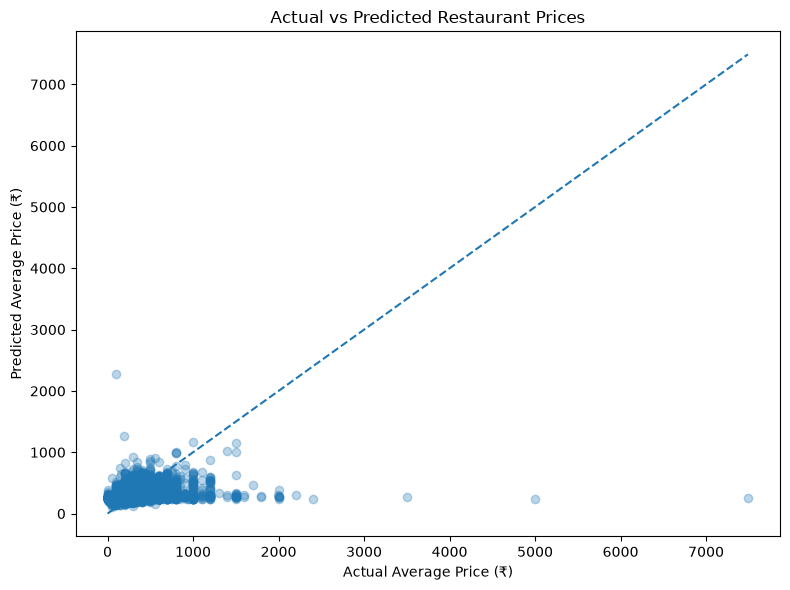

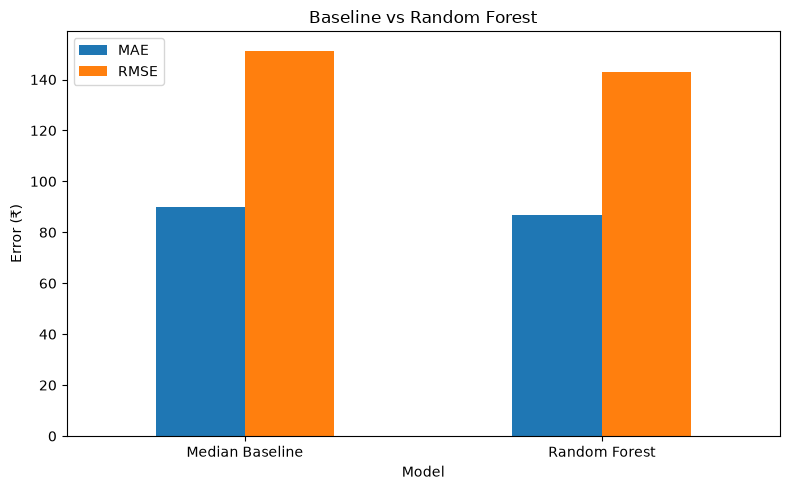

In [9]:
import matplotlib.pyplot as plt

# Graph 1: Actual vs Predicted Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Average Price (₹)")
plt.ylabel("Predicted Average Price (₹)")
plt.title("Actual vs Predicted Restaurant Prices")

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.tight_layout()
plt.show()

# Graph 2: Model comparison
comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Baseline vs Random Forest")
plt.ylabel("Error (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
new_restaurant = pd.DataFrame([{
    "cuisine": "Indian, North Indian",
    "rating": 4.0,
    "number_of_ratings": 100,
    "number_of_offers": 2,
    "offer_name": "FLAT DEAL",
    "area": "Central Abohar",
    "pure_veg": "No",
    "location": "Abohar"
}])

predicted_price = model.predict(new_restaurant)[0]

print(f"Predicted restaurant price: ₹{predicted_price:.2f}")
print("Note: This is a model estimate, not a guaranteed menu price.")

Predicted restaurant price: ₹265.40
Note: This is a model estimate, not a guaranteed menu price.


In [12]:
import joblib
from pathlib import Path

PROJECT_DIR = Path.cwd() / "swiggy_price_prediction"
PROJECT_DIR.mkdir(exist_ok=True)

MODEL_PATH = PROJECT_DIR / "swiggy_price_model.pkl"
joblib.dump(model, MODEL_PATH)

print("✅ Model saved:", MODEL_PATH.resolve())
print("Model size:", round(MODEL_PATH.stat().st_size / (1024 * 1024), 2), "MB")

✅ Model saved: C:\Users\ASUS\Documents\swiggy_price_prediction\swiggy_price_model.pkl
Model size: 14.75 MB


In [14]:
from pathlib import Path

PROJECT_DIR = Path.cwd() / "swiggy_price_prediction"
PROJECT_DIR.mkdir(exist_ok=True)

readme = (
    "# Swiggy Restaurant Price Prediction\n\n"
    "## Overview\n"
    "A machine learning regression project that predicts restaurant "
    "average prices using restaurant and offer-related features.\n\n"
    "## Dataset\n"
    f"- Cleaned records: {len(df):,}\n"
    "- Input features: 8\n"
    "- Target variable: average_price\n"
    f"- Training samples: {len(X_train):,}\n"
    f"- Testing samples: {len(X_test):,}\n\n"
    "## Technologies\n"
    "Python, pandas, NumPy, scikit-learn, Matplotlib, joblib, Jupyter Notebook.\n\n"
    "## Methodology\n"
    "1. Loaded the cleaned Swiggy dataset.\n"
    "2. Selected eight input features and average_price as the target.\n"
    "3. Split data into 80% training and 20% testing sets.\n"
    "4. Imputed missing numeric values using the median.\n"
    "5. Imputed missing categorical values using the most frequent value.\n"
    "6. Scaled numeric features and one-hot encoded categorical features.\n"
    "7. Trained a Random Forest Regressor.\n"
    "8. Compared its performance with a median baseline.\n\n"
    "## Model Evaluation\n\n"
    "| Model | MAE (INR) | RMSE (INR) | R2 Score |\n"
    "|---|---:|---:|---:|\n"
    "| Median Baseline | 89.7797 | 151.3517 | -0.0161 |\n"
    "| Random Forest | 86.8943 | 142.9538 | 0.0935 |\n\n"
    "The Random Forest performed better than the baseline on this test split. "
    "However, the R2 score is low, indicating limited predictive performance. "
    "Further feature engineering and hyperparameter tuning are recommended.\n\n"
    "## Installation\n\n"
    "Install the required libraries using:\n\n"
    "```bash\n"
    "pip install pandas numpy scikit-learn matplotlib joblib jupyter\n"
    "```\n\n"
    "## Usage\n"
    "1. Place the cleaned dataset at the path configured in the notebook.\n"
    "2. Run the notebook cells in order to train and evaluate the model.\n"
    "3. Use the saved pipeline to predict prices for new restaurant records.\n\n"
    "## Saved Model\n"
    "`swiggy_price_model.pkl` contains the preprocessing pipeline and trained model.\n\n"
    "## Limitations\n"
    "Predictions are estimates, not guaranteed menu prices. The current model "
    "has limited explanatory performance and should be improved before "
    "real-world deployment.\n"
)

readme_path = PROJECT_DIR / "README.md"
readme_path.write_text(readme, encoding="utf-8")

print("README created successfully!")
print("Path:", readme_path.resolve())
print("File size:", readme_path.stat().st_size, "bytes")

README created successfully!
Path: C:\Users\ASUS\Documents\swiggy_price_prediction\README.md
File size: 1949 bytes


In [15]:
import joblib
import numpy as np

# Save the model if it has not been saved yet
MODEL_PATH = PROJECT_DIR / "swiggy_price_model.pkl"

if not MODEL_PATH.exists():
    joblib.dump(model, MODEL_PATH)
    print("✅ Trained model saved.")

# Load and verify
loaded_model = joblib.load(MODEL_PATH)

original_prediction = model.predict(new_restaurant)[0]
loaded_prediction = loaded_model.predict(new_restaurant)[0]

print("\n=== FINAL PROJECT VERIFICATION ===")
print("README exists:", readme_path.exists())
print("Saved model exists:", MODEL_PATH.exists())
print("Original prediction: ₹", round(original_prediction, 2))
print("Loaded model prediction: ₹", round(loaded_prediction, 2))
print("Predictions match:", np.isclose(original_prediction, loaded_prediction))

assert readme_path.exists()
assert MODEL_PATH.exists()
assert np.isclose(original_prediction, loaded_prediction)

print("\n🎉 MODEL AND README VERIFIED SUCCESSFULLY!")
print("Project folder:", PROJECT_DIR.resolve())


=== FINAL PROJECT VERIFICATION ===
README exists: True
Saved model exists: True
Original prediction: ₹ 265.4
Loaded model prediction: ₹ 265.4
Predictions match: True

🎉 MODEL AND README VERIFIED SUCCESSFULLY!
Project folder: C:\Users\ASUS\Documents\swiggy_price_prediction


# Swiggy Restaurant Price Prediction

## Project Overview

This project uses Machine Learning to predict the average price of a restaurant based on its cuisine, ratings, offers, area, vegetarian status, and location.

The objective is to develop a complete regression workflow, including data preparation, preprocessing, model training, evaluation, and prediction.

## Dataset Information

- **Dataset:** Swiggy Restaurant Dataset
- **Total Records:** 139,321
- **Total Columns:** 10
- **Input Features:** 8
- **Target Variable:** `average_price`
- **Training Samples:** 111,456
- **Testing Samples:** 27,865

### Input Features

1. `cuisine`
2. `rating`
3. `number_of_ratings`
4. `number_of_offers`
5. `offer_name`
6. `area`
7. `pure_veg`
8. `location`

The `restaurant_name` column was excluded from the model inputs.

## Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Joblib
- Jupyter Notebook

## Project Workflow

### 1. Data Preparation

Loaded the cleaned dataset and selected eight input features along with `average_price` as the target variable.

### 2. Data Preprocessing

Built a Scikit-learn preprocessing pipeline.

- Missing numerical values were handled using median imputation.
- Missing categorical values were handled using most-frequent imputation.
- Numerical features were standardized using `StandardScaler`.
- Categorical features were transformed using `OneHotEncoder`.
- Unknown categories were handled using `handle_unknown="ignore"`.

### 3. Train-Test Split

Split the dataset into training and testing sets using an 80:20 ratio with `random_state=42`.

### 4. Model Training

Trained a `RandomForestRegressor` with the following configuration:

- Number of estimators: 100
- Maximum depth: 20
- Minimum samples per leaf: 2
- Random state: 42

The preprocessing steps and trained model were combined into a single Scikit-learn pipeline.

### 5. Model Evaluation

Evaluated the model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

## Model Results

| Model | MAE (₹) | RMSE (₹) | R² Score |
|---|---:|---:|---:|
| Median Baseline | 89.7797 | 151.3517 | -0.0161 |
| Random Forest Regressor | 86.8943 | 142.9538 | 0.0935 |

The Random Forest model performed better than the median baseline on this test split. However, the R² score indicates that the current model has limited predictive performance and could benefit from further feature engineering and hyperparameter tuning.

## Sample Prediction

The trained model was tested with a sample restaurant record.

**Predicted average price:** ₹265.40

This value is a model-generated estimate and is not a guaranteed restaurant price.

## Installation

Install the required Python libraries:

```bash
pip install pandas numpy scikit-learn matplotlib joblib jupyter
```

## How to Run

1. Download or clone the project files.
2. Place the cleaned dataset in the location configured in the notebook.
3. Update the dataset path if necessary.
4. Open the Jupyter Notebook.
5. Run the cells in order to preprocess the data, train the model, and evaluate its performance.
6. Use the trained pipeline to generate predictions for new restaurant records.

## Saved Model

The trained pipeline is saved as:

`swiggy_price_model.pkl`

It includes both the preprocessing steps and the trained Random Forest model.

The saved model was reloaded and tested successfully. The original and reloaded models produced matching predictions for the sample input.

## Limitations and Future Improvements

- The current R² score is low, indicating limited explanatory performance.
- Additional feature engineering may improve predictive accuracy.
- Hyperparameter tuning and alternative regression algorithms could be explored.
- Further analysis of price distributions and prediction errors may help identify opportunities for improvement.

## Conclusion

This project demonstrates an end-to-end Machine Learning regression workflow for restaurant price prediction, covering preprocessing, model training, evaluation, baseline comparison, prediction, and model persistence.

The results provide a starting point for further experimentation and model improvement.

---

**Internship:** Swynex Technologies  
**Task:** Task 4 — Complete Machine Learning Project  
**Project:** Swiggy Restaurant Price Prediction
